In [45]:
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

import src.bgnbd_diagnostics as diagnostics
importlib.reload(diagnostics)

from src.bgnbd_diagnostics import (
    make_transaction_table,
    build_customer_summary,
    diagnose_bgnbd,
    fit_bgnbd_experiment,
    fit_gamma_gamma,
    evaluate_predictions,
)

from src.config import CONFIG

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "bgnbd_diagnostics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PENALIZERS = [0.0, 0.0001, 0.001, 0.01, 0.05, 0.1]
HOLDOUT_DAYS = 90

print("Project root:", PROJECT_ROOT)
print("Output directory:", OUTPUT_DIR)
print("Penalizers:", PENALIZERS)

Project root: D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation
Output directory: D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs\bgnbd_diagnostics
Penalizers: [0.0, 0.0001, 0.001, 0.01, 0.05, 0.1]


In [46]:
DATA_PATH = CONFIG.output_dir / "cleaned_data.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {DATA_PATH}"
    )

df_clean = pd.read_csv(
    DATA_PATH,
    parse_dates=["InvoiceDate"]
)

print("Dataset shape:", df_clean.shape)
print("Jumlah customer:", df_clean["CustomerID"].nunique())
print(
    "Rentang tanggal:",
    df_clean["InvoiceDate"].min(),
    "->",
    df_clean["InvoiceDate"].max()
)

display(df_clean.head())

Dataset shape: (392693, 9)
Jumlah customer: 4338
Rentang tanggal: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [51]:
if "df_clean" not in globals():
    raise NameError(
        "df_clean belum tersedia. Jalankan Cell 2 terlebih dahulu."
    )

# Pastikan kolom yang diperlukan tersedia
required_columns = ["CustomerID", "InvoiceDate"]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom tidak ditemukan: {missing_columns}"
    )

# Pastikan tipe tanggal benar
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

df_clean = df_clean.dropna(
    subset=["CustomerID", "InvoiceDate"]
).copy()

# Tentukan periode calibration dan holdout
HOLDOUT_DAYS = 90

first_day = df_clean["InvoiceDate"].min().normalize()
last_day = df_clean["InvoiceDate"].max().normalize()

if (last_day - first_day).days <= HOLDOUT_DAYS:
    raise ValueError(
        "Rentang tanggal dataset tidak cukup untuk holdout 90 hari."
    )

cutoff = last_day - pd.Timedelta(days=HOLDOUT_DAYS)

# Batas akhir calibration bersifat eksklusif
calibration_end = cutoff + pd.Timedelta(days=1)

calibration = df_clean[
    df_clean["InvoiceDate"] < calibration_end
].copy()

holdout = df_clean[
    df_clean["InvoiceDate"] >= calibration_end
].copy()

# Validasi
if calibration.empty or holdout.empty:
    raise ValueError("Calibration atau holdout kosong.")

assert calibration["InvoiceDate"].max() < holdout["InvoiceDate"].min()

print("===== CALIBRATION AND HOLDOUT =====")
print("First date:", first_day)
print("Last date:", last_day)
print("Calibration end:", calibration_end)
print("Calibration rows:", len(calibration))
print("Holdout rows:", len(holdout))
print("Calibration customers:", calibration["CustomerID"].nunique())
print("Holdout customers:", holdout["CustomerID"].nunique())
print("Holdout duration:", HOLDOUT_DAYS, "days")

===== CALIBRATION AND HOLDOUT =====
First date: 2010-12-01 00:00:00
Last date: 2011-12-09 00:00:00
Calibration end: 2011-09-11 00:00:00
Calibration rows: 233840
Holdout rows: 158853
Calibration customers: 3370
Holdout customers: 2889
Holdout duration: 90 days


In [52]:
day_transactions = make_transaction_table(
    calibration,
    unit="day"
)

invoice_transactions = make_transaction_table(
    calibration,
    unit="invoice"
)

day_holdout = make_transaction_table(
    holdout,
    unit="day"
)

invoice_holdout = make_transaction_table(
    holdout,
    unit="invoice"
)

transaction_comparison = pd.DataFrame([
    {
        "model": "Day",
        "calibration_transactions": len(day_transactions),
        "holdout_transactions": len(day_holdout),
        "customers": day_transactions["CustomerID"].nunique(),
    },
    {
        "model": "Invoice",
        "calibration_transactions": len(invoice_transactions),
        "holdout_transactions": len(invoice_holdout),
        "customers": invoice_transactions["CustomerID"].nunique(),
    },
])

display(transaction_comparison)

,model,calibration_transactions,holdout_transactions,customers
0,Day,10807,5956,3370
1,Invoice,11906,6626,3370


In [53]:
day_summary = build_customer_summary(
    day_transactions,
    calibration_end
)

invoice_summary = build_customer_summary(
    invoice_transactions,
    calibration_end
)

summary_comparison = pd.DataFrame([
    {
        "model": "Day",
        "customers": len(day_summary),
        "mean_frequency": day_summary["frequency"].mean(),
        "mean_recency": day_summary["recency"].mean(),
        "mean_T": day_summary["T"].mean(),
        "mean_monetary": day_summary["monetary_value"].mean(),
        "frequency_zero": (day_summary["frequency"] == 0).sum(),
        "recency_zero": (day_summary["recency"] == 0).sum(),
        "T_zero": (day_summary["T"] == 0).sum(),
    },
    {
        "model": "Invoice",
        "customers": len(invoice_summary),
        "mean_frequency": invoice_summary["frequency"].mean(),
        "mean_recency": invoice_summary["recency"].mean(),
        "mean_T": invoice_summary["T"].mean(),
        "mean_monetary": invoice_summary["monetary_value"].mean(),
        "frequency_zero": (invoice_summary["frequency"] == 0).sum(),
        "recency_zero": (invoice_summary["recency"] == 0).sum(),
        "T_zero": (invoice_summary["T"] == 0).sum(),
    },
])

print("===== SUMMARY COMPARISON =====")
display(summary_comparison)

print("===== DAY SUMMARY =====")
display(day_summary.describe())

print("===== INVOICE SUMMARY =====")
display(invoice_summary.describe())

===== SUMMARY COMPARISON =====


,model,customers,mean_frequency,mean_recency,mean_T,mean_monetary,frequency_zero,recency_zero,T_zero
0,Day,3370,2.206825,87.905045,183.903264,434.225843,1414,1414,0
1,Invoice,3370,2.532938,87.905618,183.361364,397.317718,1362,1364,0


===== DAY SUMMARY =====


,CustomerID,frequency,recency,T,monetary_value,transaction_count,first_purchase,last_purchase
count,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370,3370
mean,15276.122849,2.206825,87.905045,183.903264,434.225843,3.206825,2011-03-11 02:19:17.982195712,2011-06-07 00:02:33.827893248
min,12346.000000,0.000000,0.000000,2.000000,2.900000,1.000000,2010-12-01 00:00:00,2010-12-01 00:00:00
25%,13786.250000,0.000000,0.000000,124.000000,174.732500,1.000000,2010-12-19 00:00:00,2011-04-11 06:00:00
50%,15234.500000,1.000000,55.000000,194.000000,295.965000,2.000000,2011-03-01 00:00:00,2011-06-28 00:00:00
75%,16765.750000,3.000000,170.000000,266.000000,438.135000,4.000000,2011-05-10 00:00:00,2011-08-15 00:00:00
max,18287.000000,82.000000,282.000000,284.000000,77183.600000,83.000000,2011-09-09 00:00:00,2011-09-09 00:00:00
std,1725.580817,4.626791,95.479894,80.455546,1609.485595,4.626791,NaN,NaN


===== INVOICE SUMMARY =====


,CustomerID,frequency,recency,T,monetary_value,transaction_count,first_purchase,last_purchase
count,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370.000000,3370,3370
mean,15276.122849,2.532938,87.905618,183.361364,397.317718,3.532938,2011-03-11 15:19:38.154302720,2011-06-07 13:03:43.531157248
min,12346.000000,0.000000,0.000000,1.384028,2.900000,1.000000,2010-12-01 08:26:00,2010-12-01 09:53:00
25%,13786.250000,0.000000,0.000000,123.482118,168.302500,1.000000,2010-12-19 15:00:15,2011-04-11 21:37:45
50%,15234.500000,1.000000,54.870833,193.614236,283.077000,2.000000,2011-03-01 09:15:30,2011-06-28 11:50:00
75%,16765.750000,3.000000,170.053472,265.374826,412.411000,4.000000,2011-05-10 12:25:45,2011-08-15 13:49:45
max,18287.000000,131.000000,282.022222,283.648611,77183.600000,132.000000,2011-09-09 14:47:00,2011-09-09 15:53:00
std,1725.580817,5.788414,95.478785,80.456770,1422.630474,5.788414,NaN,NaN


In [54]:
def run_penalizer_experiments(summary, model_name):
    records = []
    fitted_models = {}
    alive_results = {}

    for penalizer in PENALIZERS:

        print(
            f"Fitting {model_name} | penalizer={penalizer}"
        )

        fit_result = fit_bgnbd_experiment(
            summary,
            penalizer
        )

        record = {
            "model": model_name,
            "penalizer": penalizer,
            "converged": fit_result["converged"],
            "warnings": " | ".join(fit_result["warnings"]),
            "error": fit_result["error"],
        }

        if fit_result["converged"]:

            model = fit_result["model"]

            diagnostic, alive = diagnose_bgnbd(
                model,
                summary
            )

            params = model.params_.to_dict()

            a = params.get("a", np.nan)
            b = params.get("b", np.nan)

            record.update({
                "r": params.get("r", np.nan),
                "alpha": params.get("alpha", np.nan),
                "a": a,
                "b": b,
                "dropout_degenerate": bool(
                    min(a, b) < 0.01
                ),
                "prob_alive_mean": diagnostic["prob_alive_mean"],
                "prob_alive_std": diagnostic["prob_alive_std"],
                "prob_alive_min": diagnostic["prob_alive_min"],
                "prob_alive_median": diagnostic["prob_alive_median"],
                "prob_alive_max": diagnostic["prob_alive_max"],
                "prob_alive_unique": diagnostic["prob_alive_unique"],
                "prob_alive_all_one": diagnostic["prob_alive_all_one"],
            })

            fitted_models[penalizer] = model
            alive_results[penalizer] = alive

        else:

            record.update({
                "r": np.nan,
                "alpha": np.nan,
                "a": np.nan,
                "b": np.nan,
                "dropout_degenerate": np.nan,
                "prob_alive_mean": np.nan,
                "prob_alive_std": np.nan,
                "prob_alive_min": np.nan,
                "prob_alive_median": np.nan,
                "prob_alive_max": np.nan,
                "prob_alive_unique": np.nan,
                "prob_alive_all_one": np.nan,
            })

        records.append(record)

    return (
        pd.DataFrame(records),
        fitted_models,
        alive_results
    )

In [55]:
day_penalizer_results, day_models, day_alive = (
    run_penalizer_experiments(
        day_summary,
        "Day"
    )
)

invoice_penalizer_results, invoice_models, invoice_alive = (
    run_penalizer_experiments(
        invoice_summary,
        "Invoice"
    )
)

penalizer_comparison = pd.concat(
    [
        day_penalizer_results,
        invoice_penalizer_results
    ],
    ignore_index=True
)

print("===== PENALIZER COMPARISON =====")

display(
    penalizer_comparison[
        [
            "model",
            "penalizer",
            "converged",
            "dropout_degenerate",
            "r",
            "alpha",
            "a",
            "b",
            "prob_alive_mean",
            "prob_alive_std",
            "prob_alive_all_one",
        ]
    ]
)

penalizer_comparison.to_csv(
    OUTPUT_DIR / "penalizer_comparison.csv",
    index=False
)

Fitting Day | penalizer=0.0
Fitting Day | penalizer=0.0001
Fitting Day | penalizer=0.001
  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: -1.3581055111572835
        x: [-3.327e-01 -1.463e+00 -4.369e+01 -3.292e+01]
      nit: 33
      jac: [-5.825e-06 -2.430e-06  5.898e-07 -7.505e-07]
 hess_inv: [[ 3.036e+00  2.572e+00  2.514e+02  1.934e+02]
            [ 2.572e+00  3.753e+00  2.823e+02  2.160e+02]
            [ 2.514e+02  2.823e+02  7.653e+06  6.090e+06]
            [ 1.934e+02  2.160e+02  6.090e+06  4.847e+06]]
     nfev: 50
     njev: 47
Fitting Day | penalizer=0.01
  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: -1.3532344521020407
        x: [-3.793e-01 -1.510e+00 -4.827e+01 -3.305e+01]
      nit: 36
      jac: [-2.980e-07 -4.280e-07  5.807e-09 -6.627e-09]
 hess_inv: [[ 2.804e+00  2.515e+00  6.440e+02  4.514e+02]
            [ 2.515e+00  3.714e+00  7.4

,model,penalizer,converged,dropout_degenerate,r,alpha,a,b,prob_alive_mean,prob_alive_std,prob_alive_all_one
0,Day,0.0000,True,True,0.721186,66.174313,1.159094e-06,7.051562e+03,1.000000,1.341191e-09,True
1,Day,0.0001,True,True,0.720765,66.135401,2.335265e-18,1.013638e-09,1.000000,3.475503e-09,True
2,Day,0.0010,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Day,0.0100,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Day,0.0500,True,True,0.593105,54.283592,5.440073e-22,8.205626e-13,1.000000,1.012295e-09,True
5,Day,0.1000,True,True,0.529047,48.282690,2.618646e-19,1.808699e-09,1.000000,2.234204e-10,True
6,Invoice,0.0000,True,False,0.620695,46.380474,5.252844e-02,1.484084e+00,0.959486,8.049387e-02,False
7,Invoice,0.0001,True,False,0.620887,46.340896,4.538116e-02,1.167437e+00,0.958544,8.191313e-02,False
8,Invoice,0.0010,True,False,0.620342,46.264041,3.164400e-02,6.899951e-01,0.957953,8.359851e-02,False
9,Invoice,0.0100,True,False,0.604343,45.209943,1.551278e-02,2.988970e-01,0.961188,8.152114e-02,False


In [56]:
day_gamma_model, day_gamma_eligible = fit_gamma_gamma(
    day_summary,
    penalizer=0.001
)

invoice_gamma_model, invoice_gamma_eligible = fit_gamma_gamma(
    invoice_summary,
    penalizer=0.001
)

gamma_comparison = pd.DataFrame([
    {
        "model": "Day",
        "eligible_customers": len(day_gamma_eligible),
        **day_gamma_model.params_.to_dict()
    },
    {
        "model": "Invoice",
        "eligible_customers": len(invoice_gamma_eligible),
        **invoice_gamma_model.params_.to_dict()
    },
])

print("===== GAMMA-GAMMA COMPARISON =====")
display(gamma_comparison)

gamma_comparison.to_csv(
    OUTPUT_DIR / "gamma_comparison.csv",
    index=False
)

===== GAMMA-GAMMA COMPARISON =====


,model,eligible_customers,p,q,v
0,Day,1956,12.412430,0.898511,12.183616
1,Invoice,2008,12.259383,0.927879,12.059544


In [57]:
def evaluate_all_models(
    fitted_models,
    summary,
    holdout_transactions,
    gamma_model,
    model_name,
    horizon_days
):
    evaluations = []
    evaluation_details = {}

    for penalizer, bgf in fitted_models.items():

        print(
            f"Evaluating {model_name} | penalizer={penalizer}"
        )

        result, metrics = evaluate_predictions(
            bgf=bgf,
            summary=summary,
            holdout_transactions=holdout_transactions,
            horizon_days=horizon_days,
            gamma_model=gamma_model,
        )

        metrics["model"] = model_name
        metrics["penalizer"] = penalizer

        evaluations.append(metrics)

        evaluation_details[(
            model_name,
            penalizer
        )] = result

    return pd.DataFrame(evaluations), evaluation_details


day_evaluation_results, day_evaluation_details = (
    evaluate_all_models(
        fitted_models=day_models,
        summary=day_summary,
        holdout_transactions=day_holdout,
        gamma_model=day_gamma_model,
        model_name="Day",
        horizon_days=HOLDOUT_DAYS,
    )
)

invoice_evaluation_results, invoice_evaluation_details = (
    evaluate_all_models(
        fitted_models=invoice_models,
        summary=invoice_summary,
        holdout_transactions=invoice_holdout,
        gamma_model=invoice_gamma_model,
        model_name="Invoice",
        horizon_days=HOLDOUT_DAYS,
    )
)

evaluation_comparison = pd.concat(
    [
        day_evaluation_results,
        invoice_evaluation_results
    ],
    ignore_index=True
)

print("===== HOLDOUT EVALUATION =====")
display(evaluation_comparison)

evaluation_comparison.to_csv(
    OUTPUT_DIR / "evaluation_comparison.csv",
    index=False
)

Evaluating Day | penalizer=0.0
Evaluating Day | penalizer=0.0001
Evaluating Day | penalizer=0.05
Evaluating Day | penalizer=0.1
Evaluating Invoice | penalizer=0.0
Evaluating Invoice | penalizer=0.0001
Evaluating Invoice | penalizer=0.001
Evaluating Invoice | penalizer=0.01
Evaluating Invoice | penalizer=0.05
Evaluating Invoice | penalizer=0.1
===== HOLDOUT EVALUATION =====


,purchase_evaluated_customers,purchase_total_customers,purchase_excluded_customers,predicted_purchases_total,actual_purchases_total,purchase_MAE,purchase_RMSE,purchase_Spearman,revenue_evaluated_customers,revenue_total_customers,predicted_revenue_total,actual_revenue_total,revenue_Spearman,model,penalizer
0,1956,3370,1414,2776.258998,3659.0,1.151428,1.827325,0.499629,1956,3370,1.395760e+06,2355079.531,0.566811,Day,0.0000
1,1956,3370,1414,2776.382043,3659.0,1.151411,1.827241,0.499594,1956,3370,1.395832e+06,2355079.531,0.566810,Day,0.0001
2,1956,3370,1414,2816.455185,3659.0,1.146010,1.801451,0.498802,1956,3370,1.419004e+06,2355079.531,0.567666,Day,0.0500
3,1956,3370,1414,2839.006406,3659.0,1.143345,1.788241,0.498446,1956,3370,1.431823e+06,2355079.531,0.567926,Day,0.1000
4,2006,3370,1364,3134.075450,4215.0,1.316487,2.576221,0.509956,2006,3370,1.448260e+06,2365276.521,0.569757,Invoice,0.0000
5,2006,3370,1364,3137.881443,4215.0,1.315903,2.574475,0.510323,2006,3370,1.450204e+06,2365276.521,0.570174,Invoice,0.0001
6,2006,3370,1364,3151.350008,4215.0,1.315143,2.570917,0.510615,2006,3370,1.456613e+06,2365276.521,0.570808,Invoice,0.0010
7,2006,3370,1364,3186.074902,4215.0,1.314795,2.563547,0.509326,2006,3370,1.472671e+06,2365276.521,0.570905,Invoice,0.0100
8,2006,3370,1364,3231.321699,4215.0,1.314079,2.547587,0.507462,2006,3370,1.494158e+06,2365276.521,0.570231,Invoice,0.0500
9,2006,3370,1364,3257.491843,4215.0,1.313126,2.535236,0.506452,2006,3370,1.506953e+06,2365276.521,0.570042,Invoice,0.1000


In [58]:
alive_records = []

for penalizer, alive in day_alive.items():
    alive_records.append({
        "model": "Day",
        "penalizer": penalizer,
        "mean": alive.mean(),
        "std": alive.std(),
        "min": alive.min(),
        "median": alive.median(),
        "max": alive.max(),
        "unique_values": alive.nunique(),
        "all_one": bool(
            np.allclose(alive.dropna().to_numpy(), 1.0)
        ),
    })

for penalizer, alive in invoice_alive.items():
    alive_records.append({
        "model": "Invoice",
        "penalizer": penalizer,
        "mean": alive.mean(),
        "std": alive.std(),
        "min": alive.min(),
        "median": alive.median(),
        "max": alive.max(),
        "unique_values": alive.nunique(),
        "all_one": bool(
            np.allclose(alive.dropna().to_numpy(), 1.0)
        ),
    })

alive_comparison = pd.DataFrame(alive_records)

print("===== PROBABILITY ALIVE COMPARISON =====")
display(alive_comparison)

alive_comparison.to_csv(
    OUTPUT_DIR / "alive_comparison.csv",
    index=False
)

===== PROBABILITY ALIVE COMPARISON =====


,model,penalizer,mean,std,min,median,max,unique_values,all_one
0,Day,0.0000,1.000000,1.341191e-09,9.999999e-01,1.000000,1.0,1922,True
1,Day,0.0001,1.000000,3.475503e-09,1.000000e+00,1.000000,1.0,673,True
2,Day,0.0500,1.000000,1.012295e-09,1.000000e+00,1.000000,1.0,672,True
3,Day,0.1000,1.000000,2.234204e-10,1.000000e+00,1.000000,1.0,672,True
4,Invoice,0.0000,0.959486,8.049387e-02,3.577703e-26,0.986779,1.0,2009,False
5,Invoice,0.0001,0.958544,8.191313e-02,4.003682e-26,0.987796,1.0,2009,False
6,Invoice,0.0010,0.957953,8.359851e-02,5.407897e-26,0.990619,1.0,2009,False
7,Invoice,0.0100,0.961188,8.152114e-02,5.894456e-26,0.994978,1.0,2009,False
8,Invoice,0.0500,0.966025,7.699774e-02,7.901960e-27,0.997602,1.0,2009,False
9,Invoice,0.1000,0.967724,7.579189e-02,8.055691e-28,0.998342,1.0,2009,False


In [59]:
print("===== PENALIZER COMPARISON =====")

display(
    penalizer_comparison[
        [
            "model", "penalizer",
            "converged", "dropout_degenerate",
            "r", "alpha", "a", "b",
            "prob_alive_mean",
            "prob_alive_std",
            "prob_alive_all_one"
        ]
    ]
)

print("\n===== HOLDOUT EVALUATION =====")

display(evaluation_comparison)

print("\n===== PROBABILITY ALIVE =====")

display(alive_comparison)

===== PENALIZER COMPARISON =====


,model,penalizer,converged,dropout_degenerate,r,alpha,a,b,prob_alive_mean,prob_alive_std,prob_alive_all_one
0,Day,0.0000,True,True,0.721186,66.174313,1.159094e-06,7.051562e+03,1.000000,1.341191e-09,True
1,Day,0.0001,True,True,0.720765,66.135401,2.335265e-18,1.013638e-09,1.000000,3.475503e-09,True
2,Day,0.0010,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Day,0.0100,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Day,0.0500,True,True,0.593105,54.283592,5.440073e-22,8.205626e-13,1.000000,1.012295e-09,True
5,Day,0.1000,True,True,0.529047,48.282690,2.618646e-19,1.808699e-09,1.000000,2.234204e-10,True
6,Invoice,0.0000,True,False,0.620695,46.380474,5.252844e-02,1.484084e+00,0.959486,8.049387e-02,False
7,Invoice,0.0001,True,False,0.620887,46.340896,4.538116e-02,1.167437e+00,0.958544,8.191313e-02,False
8,Invoice,0.0010,True,False,0.620342,46.264041,3.164400e-02,6.899951e-01,0.957953,8.359851e-02,False
9,Invoice,0.0100,True,False,0.604343,45.209943,1.551278e-02,2.988970e-01,0.961188,8.152114e-02,False



===== HOLDOUT EVALUATION =====


,purchase_evaluated_customers,purchase_total_customers,purchase_excluded_customers,predicted_purchases_total,actual_purchases_total,purchase_MAE,purchase_RMSE,purchase_Spearman,revenue_evaluated_customers,revenue_total_customers,predicted_revenue_total,actual_revenue_total,revenue_Spearman,model,penalizer
0,1956,3370,1414,2776.258998,3659.0,1.151428,1.827325,0.499629,1956,3370,1.395760e+06,2355079.531,0.566811,Day,0.0000
1,1956,3370,1414,2776.382043,3659.0,1.151411,1.827241,0.499594,1956,3370,1.395832e+06,2355079.531,0.566810,Day,0.0001
2,1956,3370,1414,2816.455185,3659.0,1.146010,1.801451,0.498802,1956,3370,1.419004e+06,2355079.531,0.567666,Day,0.0500
3,1956,3370,1414,2839.006406,3659.0,1.143345,1.788241,0.498446,1956,3370,1.431823e+06,2355079.531,0.567926,Day,0.1000
4,2006,3370,1364,3134.075450,4215.0,1.316487,2.576221,0.509956,2006,3370,1.448260e+06,2365276.521,0.569757,Invoice,0.0000
5,2006,3370,1364,3137.881443,4215.0,1.315903,2.574475,0.510323,2006,3370,1.450204e+06,2365276.521,0.570174,Invoice,0.0001
6,2006,3370,1364,3151.350008,4215.0,1.315143,2.570917,0.510615,2006,3370,1.456613e+06,2365276.521,0.570808,Invoice,0.0010
7,2006,3370,1364,3186.074902,4215.0,1.314795,2.563547,0.509326,2006,3370,1.472671e+06,2365276.521,0.570905,Invoice,0.0100
8,2006,3370,1364,3231.321699,4215.0,1.314079,2.547587,0.507462,2006,3370,1.494158e+06,2365276.521,0.570231,Invoice,0.0500
9,2006,3370,1364,3257.491843,4215.0,1.313126,2.535236,0.506452,2006,3370,1.506953e+06,2365276.521,0.570042,Invoice,0.1000



===== PROBABILITY ALIVE =====


,model,penalizer,mean,std,min,median,max,unique_values,all_one
0,Day,0.0000,1.000000,1.341191e-09,9.999999e-01,1.000000,1.0,1922,True
1,Day,0.0001,1.000000,3.475503e-09,1.000000e+00,1.000000,1.0,673,True
2,Day,0.0500,1.000000,1.012295e-09,1.000000e+00,1.000000,1.0,672,True
3,Day,0.1000,1.000000,2.234204e-10,1.000000e+00,1.000000,1.0,672,True
4,Invoice,0.0000,0.959486,8.049387e-02,3.577703e-26,0.986779,1.0,2009,False
5,Invoice,0.0001,0.958544,8.191313e-02,4.003682e-26,0.987796,1.0,2009,False
6,Invoice,0.0010,0.957953,8.359851e-02,5.407897e-26,0.990619,1.0,2009,False
7,Invoice,0.0100,0.961188,8.152114e-02,5.894456e-26,0.994978,1.0,2009,False
8,Invoice,0.0500,0.966025,7.699774e-02,7.901960e-27,0.997602,1.0,2009,False
9,Invoice,0.1000,0.967724,7.579189e-02,8.055691e-28,0.998342,1.0,2009,False


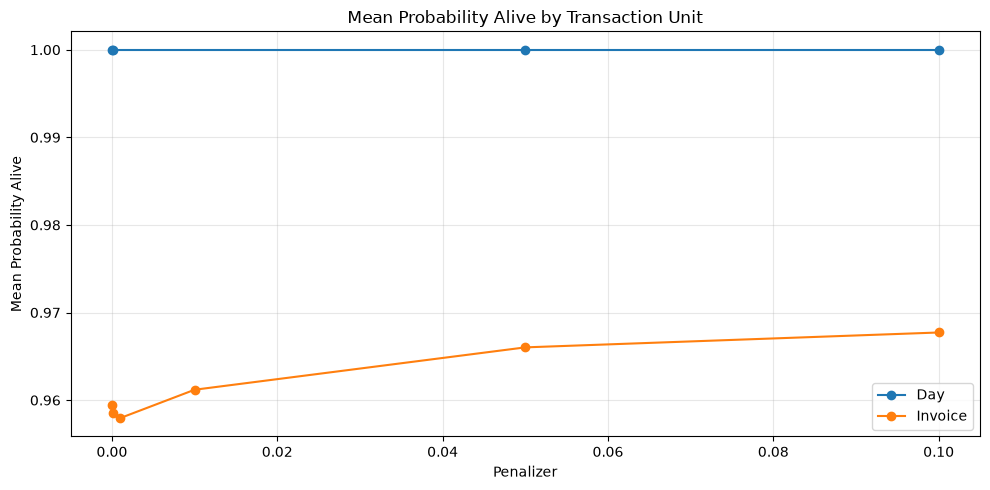

In [60]:
fig, ax = plt.subplots(figsize=(10, 5))

for model_name in ["Day", "Invoice"]:

    subset = alive_comparison[
        alive_comparison["model"] == model_name
    ]

    ax.plot(
        subset["penalizer"],
        subset["mean"],
        marker="o",
        label=model_name
    )

ax.set_xlabel("Penalizer")
ax.set_ylabel("Mean Probability Alive")
ax.set_title("Mean Probability Alive by Transaction Unit")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "probability_alive_mean.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

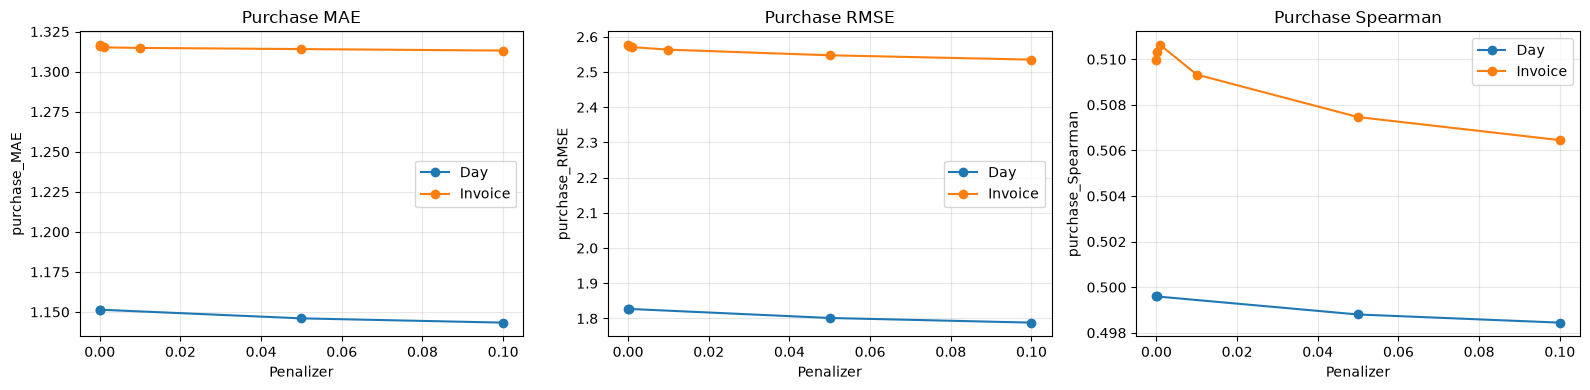

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

metrics_to_plot = [
    ("purchase_MAE", "Purchase MAE"),
    ("purchase_RMSE", "Purchase RMSE"),
    ("purchase_Spearman", "Purchase Spearman"),
]

for ax, (metric, title) in zip(axes, metrics_to_plot):

    for model_name in ["Day", "Invoice"]:

        subset = evaluation_comparison[
            evaluation_comparison["model"] == model_name
        ].sort_values("penalizer")

        ax.plot(
            subset["penalizer"],
            subset[metric],
            marker="o",
            label=model_name
        )

    ax.set_title(title)
    ax.set_xlabel("Penalizer")
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "holdout_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [62]:
for (model_name, penalizer), result in {
    **day_evaluation_details,
    **invoice_evaluation_details
}.items():

    filename = (
        f"{model_name.lower()}_"
        f"penalizer_{str(penalizer).replace('.', '_')}.csv"
    )

    result.to_csv(
        OUTPUT_DIR / filename,
        index=False
    )

print("Seluruh hasil evaluasi pelanggan berhasil disimpan.")
print("Lokasi:", OUTPUT_DIR)

Seluruh hasil evaluasi pelanggan berhasil disimpan.
Lokasi: D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs\bgnbd_diagnostics


In [63]:
print("===== FINAL EXPERIMENT SUMMARY =====")

print("\nJumlah model Day yang berhasil di-fit:",
      len(day_models))

print("Jumlah model Invoice yang berhasil di-fit:",
      len(invoice_models))

print("\nJumlah evaluasi Day:",
      len(day_evaluation_results))

print("Jumlah evaluasi Invoice:",
      len(invoice_evaluation_results))

print("\n===== CUSTOMER COVERAGE =====")

coverage_columns = [
    "model",
    "penalizer",
    "purchase_evaluated_customers",
    "purchase_total_customers",
    "purchase_excluded_customers",
    "revenue_evaluated_customers",
]

display(
    evaluation_comparison[coverage_columns]
)

print("\nOutput tersimpan di:", OUTPUT_DIR)

===== FINAL EXPERIMENT SUMMARY =====

Jumlah model Day yang berhasil di-fit: 4
Jumlah model Invoice yang berhasil di-fit: 6

Jumlah evaluasi Day: 4
Jumlah evaluasi Invoice: 6

===== CUSTOMER COVERAGE =====


,model,penalizer,purchase_evaluated_customers,purchase_total_customers,purchase_excluded_customers,revenue_evaluated_customers
0,Day,0.0000,1956,3370,1414,1956
1,Day,0.0001,1956,3370,1414,1956
2,Day,0.0500,1956,3370,1414,1956
3,Day,0.1000,1956,3370,1414,1956
4,Invoice,0.0000,2006,3370,1364,2006
5,Invoice,0.0001,2006,3370,1364,2006
6,Invoice,0.0010,2006,3370,1364,2006
7,Invoice,0.0100,2006,3370,1364,2006
8,Invoice,0.0500,2006,3370,1364,2006
9,Invoice,0.1000,2006,3370,1364,2006



Output tersimpan di: D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs\bgnbd_diagnostics
